In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)


import numpy as np
import matplotlib.pyplot as plt
import pywt
from PIL import Image
import tensorflow as tf

import tensorflow_wavelets.Layers.DWT as DWT
from tensorflow import keras

from layers.Wavelet3D import DWT3D, IDWT3D


from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil

import utils.functions as fc


In [2]:
# wavelet = pywt.Wavelet("bior1.3")
# lpf = wavelet.dec_lo
# hpf = wavelet.dec_hi
# print(lpf)  
# print(hpf)

In [3]:
input_shape = (192,224,192)

data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED, 
                                batch_size=1, 
                                image_size=input_shape, 
                                channels_first=False,  
                                shuffle=False, 
                                shuffle_before_selecting=False, 
                                nb_patients=-1, 
                                server=False,
                                )

layer = 116
# Cargar la imagen

image3D = data_train[0][0]
image3D2 = data_train[1][0]
image = image3D[0,...,layer,0]
image /= np.max(image)

# Wavelet Transform 2D

In [4]:
def visualize_wevelet_filters_result(image, LL, LH, HL, HH):
    # Visualizar la imagen original y los detalles obtenidos
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 5, 1)
    plt.imshow(image, cmap='gray')
    plt.title('Imagen Original')
    plt.axis('off')

    plt.subplot(1, 5, 2)
    plt.imshow(LL, cmap='gray')
    plt.title('LL')
    plt.axis('off')

    plt.subplot(1, 5, 3)
    plt.imshow(LH, cmap='gray')
    plt.title('LH')
    plt.axis('off')

    plt.subplot(1, 5, 4)
    plt.imshow(HL, cmap='gray')
    plt.title('HL')
    plt.axis('off')

    plt.subplot(1, 5, 5)
    plt.imshow(HH, cmap='gray')
    plt.title('HH')
    plt.axis('off')

    plt.show()



def apply_my_wavelet_filter(image):
    # haar_lowpass_filter = np.array([1, 1]) / np.sqrt(2)
    # haar_high_pass_filter = np.array([-1, 1]) / np.sqrt(2)

    wavelet = pywt.Wavelet("haar")
    lpf = wavelet.dec_lo[::-1]
    hpf = wavelet.dec_hi[::-1]

    dec_len = wavelet.dec_len
    
    # Aplicar la transformada wavelet in the rows to fin L and H
    inputs_pad = np.pad(image, ((0,0), (dec_len-1, dec_len-1)), mode='symmetric')
    L = np.zeros(inputs_pad.shape)
    H = np.zeros(inputs_pad.shape)

    for i in range(inputs_pad.shape[0]):
        L[i, :-1] = np.convolve(inputs_pad[i], lpf, mode='valid')
        H[i, :-1] = np.convolve(inputs_pad[i], hpf, mode='valid')

    L = L[:, 1:L.shape[1]-1:2]
    H = H[:, 1:H.shape[1]-1:2]
        
    L = np.pad(L, ((dec_len-1, dec_len-1), (0,0)), mode='symmetric')
    H = np.pad(H, ((dec_len-1, dec_len-1), (0,0)), mode='symmetric')

    # Aplicar la transformada wavelet in the columna to fin LL and HH and LH and HL
    LL = np.zeros(L.shape)
    LH = np.zeros(L.shape)
    HL = np.zeros(L.shape)
    HH = np.zeros(L.shape)
    for j in range(L.shape[1]):
        LL[:-1, j] = np.convolve(L[:, j], lpf, mode='valid')
        LH[:-1, j] = np.convolve(L[:, j], hpf, mode='valid')
        HL[:-1, j] = np.convolve(H[:, j], lpf, mode='valid')
        HH[:-1, j] = np.convolve(H[:, j], hpf, mode='valid')

    # submuestrar las imagenes
    LL = LL[1:LL.shape[0]-1:2, :]
    LH = LH[1:LH.shape[0]-1:2, :]
    HL = HL[1:HL.shape[0]-1:2, :]
    HH = HH[1:HH.shape[0]-1:2, :]

    return LL, LH, HL, HH


def DWT_tf(image, name="haar"):
    model = keras.Sequential()
    model.add(keras.Input(shape=(image.shape + (1,))))
    model.add(DWT.DWT(name=name,concat=0))
    image_tf = np.expand_dims(np.expand_dims(image, axis=0), axis=-1)
    res = model(image_tf)
    LL_tf, LH_tf, HL_tf, HH_tf = res[0,...,0], res[0,...,1], res[0,...,2], res[0,...,3]
    return LL_tf, LH_tf, HL_tf, HH_tf


def dwt_np(image, wavelet_name='haar'):
    # get filter coeffs from pywavelet library
    wavelet = pywt.Wavelet(wavelet_name)
    dec_len = wavelet.dec_len

    # decomposition filter low pass and high pass coeffs
    lpf = wavelet.dec_lo
    hpf = wavelet.dec_hi

    # pad input image
    inputs_pad = np.pad(image, ((0,0), (dec_len-1, dec_len-1)), mode='symmetric')

    # convolution with low pass and high pass filters
    l = np.array([np.convolve(inputs_pad[x], lpf[::-1], mode='valid') for x in range(inputs_pad.shape[0])])
    h = np.array([np.convolve(inputs_pad[x], hpf[::-1], mode='valid') for x in range(inputs_pad.shape[0])])

    # down sample
    l = l[:, 1:l.shape[1]:2]
    h = h[:, 1:h.shape[1]:2]

    # pad downsampled components
    l = np.pad(l, ((dec_len-1, dec_len-1), (0, 0)), mode='symmetric')
    h = np.pad(h, ((dec_len-1, dec_len-1), (0, 0)), mode='symmetric')

    # transpose for column-wise convolution
    l = np.transpose(l, (1, 0))
    h = np.transpose(h, (1, 0))

    # perform convolution
    ll = np.array([np.convolve(l[y], lpf[::-1], mode='valid') for y in range(l.shape[0])])
    lh = np.array([np.convolve(l[y], hpf[::-1], mode='valid') for y in range(l.shape[0])])
    hl = np.array([np.convolve(h[y], lpf[::-1], mode='valid') for y in range(h.shape[0])])
    hh = np.array([np.convolve(h[y], hpf[::-1], mode='valid') for y in range(h.shape[0])])

    # transpose back
    ll = np.transpose(ll, (1, 0))
    lh = np.transpose(lh, (1, 0))
    hl = np.transpose(hl, (1, 0))
    hh = np.transpose(hh, (1, 0))

    # down sample
    ll = ll[1:ll.shape[0]:2, :]
    lh = lh[1:lh.shape[0]:2, :]
    hl = hl[1:hl.shape[0]:2, :]
    hh = hh[1:hh.shape[0]:2, :]

    return ll, lh, hl, hh


### Inverse

In [5]:
def upsampler2d(x):
    """
    up sampling with zero insertion between rows and columns
    :param x: 4 dim tensor (?, w, h, ch)
    :return:  up sampled tensor with shape (?, 2*w, 2*h, ch)
    """
    # create zero like tensor
    zero_tensor = tf.zeros_like(x)
    # stack both tensors
    stack_rows = tf.stack([x, zero_tensor], axis=3)
    # reshape for zero insertion between the rows
    stack_rows = tf.reshape(stack_rows, shape=[-1, x.shape[1], x.shape[2]*2, x.shape[3]])
    # create zero like tensor but now like the padded one
    zero_tensor_1 = tf.zeros_like(stack_rows)
    # stack both tensors
    stack_rows_cols = tf.stack([stack_rows, zero_tensor_1], axis=2)
    # reshape for zero insertion between the columns
    us_padded = tf.reshape(stack_rows_cols, shape=[-1, x.shape[1]*2, x.shape[2]*2, x.shape[3]])
    return us_padded

def upsampler2d_tf(x):
    us_padded = tf.image.resize(x, size=[x.shape[1]*2, x.shape[2]*2])
    return us_padded

def downsampler2d_tf(x):
    us_padded = tf.image.resize(x, size=[x.shape[1]//2, x.shape[2]//2])
    return us_padded

def DWT_tf_tensor(image, name="haar"):
    model = keras.Sequential()
    model.add(keras.Input(shape=(image.shape + (1,))))
    model.add(DWT.DWT(name=name,concat=0))
    image_tf = np.expand_dims(np.expand_dims(image, axis=0), axis=-1)
    return model(image_tf)


def IDWT_tf(image_dwt, name="haar"):
    model = keras.Sequential()
    model.add(keras.Input(shape=(image_dwt.shape[1:])))
    model.add(DWT.IDWT(name=name,concat=0))
    # image_dwt = np.expand_dims(image_dwt, axis=0)
    res = model(image_dwt)
    return res




In [6]:

def test_upsamplert_2D():
    # image3D = np.transpose(image3D, (4, 1, 2, 3, 0))
    image3D_down = image3D[:, 1:image3D.shape[1]:2, 1:image3D.shape[2]:2, 116, :]
    image3D_down_tf = downsampler2d_tf(image3D[:, :,:, 116, :])


    img_up = upsampler2d(image3D_down)
    img_up_tf = upsampler2d_tf(image3D_down_tf)

    print(image3D.shape)
    print(image3D_down.shape)
    print(image3D_down_tf.shape)
    print(img_up.shape)
    print(img_up_tf.shape)


    img_nb = 1
    fc.imgshow_matplotlib("", image3D[img_nb,:,:,116,:])
    fc.imgshow_matplotlib("", image3D_down[img_nb])
    fc.imgshow_matplotlib("", image3D_down_tf[img_nb])
    fc.imgshow_matplotlib("", img_up[img_nb])
    fc.imgshow_matplotlib("", img_up_tf[img_nb])

# test_upsamplert_2D()

In [7]:

# # pywt approach
# LL_dwt2, (LH_dwt2, HL_dwt2, HH_dwt2) = pywt.dwt2(image, 'haar')  # Se usa la wavelet de Haar en este ejemplo

# LL, LH, HL, HH = apply_my_wavelet_filter(image)
# LL_tf, LH_tf, HL_tf, HH_tf = DWT_tf(image)
# LL_dwt_np, LH_dwt_np, HL_dwt_np, HH_dwt_np = dwt_np(image, "haar")

# # print(np.sum(np.abs(HH - HH_dwt2)))
# # print(np.sum(np.abs(LL - LL_dwt2)))

# # print(LH_dwt2.shape)
# print(LH.shape)
# # print(LL_dwt_np.shape)

# visualize_wevelet_filters_result(image, LL_dwt2, LH_dwt2, HL_dwt2, HH_dwt2)
# visualize_wevelet_filters_result(image, LL, LH, HL, HH)
# visualize_wevelet_filters_result(image, LL_dwt_np, LH_dwt_np, HL_dwt_np, HH_dwt_np)
# visualize_wevelet_filters_result(image, LL_tf, LH_tf, HL_tf, HH_tf)


# # fc.imgshow_matplotlib("", np.abs(LL - LL_dwt2))
# # fc.imgshow_matplotlib("", np.abs(LL - LL_tf))
# # fc.imgshow_matplotlib("", np.abs(LL_dwt2 - LL_tf))

# print(np.sum(np.abs(HH_dwt2 - HH)))
# print(np.sum(np.abs(HH_dwt2 - HH_dwt_np)))
# print(np.sum(np.abs(HH_dwt2 - HH_tf)))





# # copute transform
# pywt_dwt = pywt.dwt2(image, 'haar')  # Se usa la wavelet de Haar en este ejemplo
# dwt_tf = DWT_tf_tensor(image)


# # copute inverse
# rec_pywt = pywt.idwt2(pywt_dwt, 'haar')
# rec_pywt2 = pywt.idwt2((dwt_tf[0,...,0], (dwt_tf[0,...,1], dwt_tf[0,...,2], dwt_tf[0,...,3])), 'haar')


# rec_tf = IDWT_tf(dwt_tf).numpy()[0,...,0]
# rec_pywt2tf = np.expand_dims(np.stack([pywt_dwt[0], pywt_dwt[1][0], pywt_dwt[1][1], pywt_dwt[1][2]], axis=-1), axis=0)
# rec_tf2 = IDWT_tf(rec_pywt2tf).numpy()[0,...,0]

# print(np.sum(np.abs(rec_tf - image)))
# print(np.sum(np.abs(rec_tf2 - image)))
# print(np.sum(np.abs(rec_pywt2 - image)))
# print(np.sum(np.abs(rec_pywt - image)))


# visualize_wevelet_filters_result(image, rec_pywt, rec_pywt2, rec_tf, rec_tf2)



# Wavelet transform 3D

In [8]:
def resize3D_tf(x, down=True):
    x = x[:,:,:,:,0]
    if down:
        new_shapes = [x.shape[1]//2, x.shape[2]//2, x.shape[3]//2]
    else:
        new_shapes = [x.shape[1]*2, x.shape[2]*2, x.shape[3]*2]
    x_rezised_z_y = tf.image.resize(tf.transpose(x, (0, 3, 2, 1)), size=[new_shapes[2], new_shapes[1]])
    x_rezised_z_y = tf.transpose(x_rezised_z_y, (0, 3, 2, 1))
    x_rezised_z_y = tf.image.resize(x_rezised_z_y, size=[new_shapes[0], new_shapes[1]])
    return tf.expand_dims(x_rezised_z_y, axis = -1)

def upsample_3D(x):
    upsample_layer = tf.keras.layers.UpSampling3D(size=(2, 2, 2))
    return upsample_layer(x)

def upsampler3d(x):
    """
    Up sampling with zero insertion between the slices, rows, and columns.
    :param x: 5 dim tensor (batch_size, w, h, d, ch)
    :return:  up sampled tensor with shape (batch_size, 2*w, 2*h, 2*d, ch)
    """

    # ---- upsample Z axis
    # Create zero tensor of the same shape
    zero_tensor = tf.zeros_like(x)
    # Stack tensors along the channel axis
    stack_slices = tf.stack([x, zero_tensor], axis=4)
    # Reshape for zero insertion between the slices
    stack_slices = tf.reshape(stack_slices, shape=[-1, x.shape[1], x.shape[2], x.shape[3]*2, x.shape[4]])
    
    # ---- upsample Y axis
    # Transpose in order to insert zeros for the rows
    stack_slices = tf.transpose(stack_slices, perm=[0, 1, 3, 2, 4])
    # Create zero tensor like the padded one
    zero_tensor_1 = tf.zeros_like(stack_slices)
    # Stack tensors along the channel axis
    stack_rows = tf.stack([stack_slices, zero_tensor_1], axis=4)
    # Reshape for zero insertion between the rows
    stack_rows = tf.reshape(stack_rows, shape=[-1, x.shape[1], x.shape[2]*2, x.shape[3]*2, x.shape[4]])
    # Transpose back
    stack_rows = tf.transpose(stack_rows, perm=[0, 1, 3, 2, 4])
    
    # ---- upsample X axis
    # Transpose in order to insert zeros for the columns
    stack_rows = tf.transpose(stack_rows, perm=[0, 3, 2, 1, 4])
    # Create zero tensor like the padded one
    zero_tensor_2 = tf.zeros_like(stack_rows)
    # Stack tensors along the channel axis
    stack_cols = tf.stack([stack_rows, zero_tensor_2], axis=4)
    # Reshape for zero insertion between the columns
    us_padded = tf.reshape(stack_cols, shape=[-1, x.shape[1]*2, x.shape[2]*2, x.shape[3]*2, x.shape[4]])
    # transpose back to normal
    us_padded = tf.transpose(us_padded, perm=[0, 3, 2, 1, 4])
    
    return us_padded

In [9]:

def test_upsamplert_3D():
    %matplotlib widget

    # image3D = np.transpose(image3D, (4, 1, 2, 3, 0))
    image3D_down = image3D[:, 1:image3D.shape[1]:2, 1:image3D.shape[2]:2, 1:image3D.shape[3]:2, :]
    image3D_down_tf = resize3D_tf(image3D, down=True)


    img_up = upsampler3d(image3D_down)
    # img_up_tf = resize3D_tf(image3D_down_tf, down=False)
    img_up_tf = upsample_3D(image3D_down_tf)

    print("image3D", image3D.shape)
    print("image3D_down",image3D_down.shape)
    print("image3D_down_tf",image3D_down_tf.shape)
    print("img_up",img_up.shape)
    print("img_up_tf",img_up_tf.shape)


    img_nb = 0
    current_plane = 80
    fc.imgshow_3D("", image3D[img_nb], current_plane=current_plane)
    fc.imgshow_3D("", image3D_down[img_nb], current_plane=current_plane)
    fc.imgshow_3D("", image3D_down_tf[img_nb], current_plane=current_plane)
    fc.imgshow_3D("", img_up[img_nb], current_plane=current_plane)
    fc.imgshow_3D("", img_up_tf[img_nb], current_plane=current_plane)

# test_upsamplert_3D()

In [10]:

def visualize_wevelet_filters_result3D(image, LLL, LLH, LHL, LHH, HLL, HLH, HHL, HHH, layer=50):
    plt.figure(figsize=(24, 8))
    names = [['Imagen Original', 'LLL', 'LLH', 'LHL', 'LHH'],
             ['Imagen Original', 'HLL', 'HLH', 'HHL', 'HHH']]

    imgs = [[image[...,layer*2], LLL[...,layer], LLH[...,layer], LHL[...,layer], LHH[...,layer]],
            [image[...,layer*2], HLL[...,layer], HLH[...,layer], HHL[...,layer], HHH[...,layer]]]
    c = 1
    for i in range(2):
        for j in range(5):
            plt.subplot(2, 5, c)
            plt.imshow(imgs[i][j], cmap='gray')
            plt.title(names[i][j])
            plt.axis('off')
            c +=1

    plt.show()

0.06918681


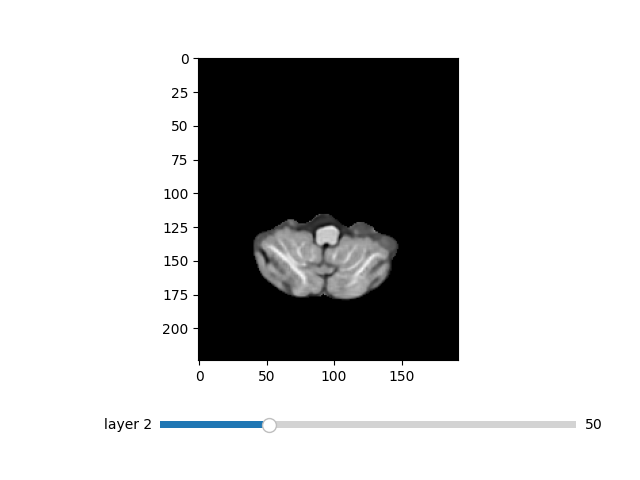

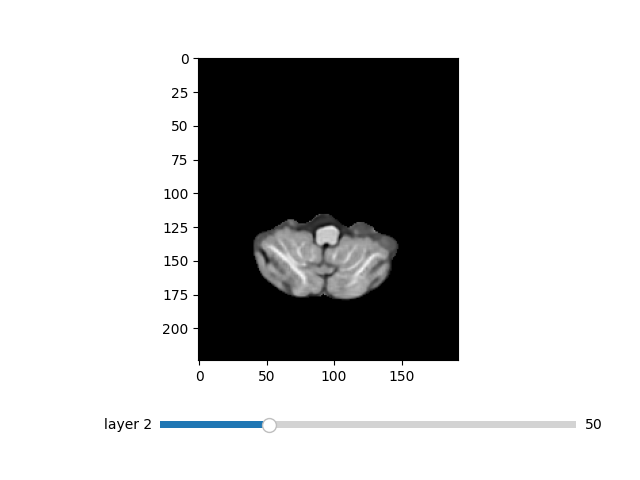

In [11]:
def wavelet_filter_3D(image3D, name="haar"):
    model = keras.Sequential()
    model.add(keras.Input(shape=(image3D.shape[1:])))
    model.add(DWT3D(name=name, wavelet_name=name))

    res = model(image3D)
    return res[0,...,0], res[0,...,1], res[0,...,2], res[0,...,3], res[0,...,4], res[0,...,5], res[0,...,6], res[0,...,7]


def wavelet_filter_3D_tensor(image3D, name="haar"):
    model = keras.Sequential()
    model.add(keras.Input(shape=(image3D.shape[1:])))
    model.add(DWT3D(name=name, wavelet_name=name))
    return model(image3D)

def inverse_wavelet_filter_3D(image3D_dwt, name="haar"):
    model = keras.Sequential()
    # print(*image3D_dwt.shape[1:4], 8)
    model.add(keras.Input(shape=(*image3D_dwt.shape[1:4], 8)))
    model.add(IDWT3D(name=name, wavelet_name=name))

    res = model(image3D_dwt)
    return res


# %matplotlib widget
# res = wavelet_filter_3D_tensor(image3D, "haar")
# rec = inverse_wavelet_filter_3D(res, "haar")

# print(np.sum(np.abs(image3D - rec)))

# # # img_3D_up = upsampler3d(image3D)
# # # print(image3D.shape)
# # # print(img_3D_up.shape)


# batch3D = np.concatenate([image3D[:, 100:164, 100:164, 100:164, :], image3D2[:, 100:164, 100:164, 100:164, :]], axis=0)
batch3D = np.concatenate([image3D, image3D2], axis=0)

# res = wavelet_filter_3D_tensor(batch3D, "haar")
# rec = inverse_wavelet_filter_3D(res, "haar")
# print()

# res1 = wavelet_filter_3D_tensor(batch3D, "sym2")
# rec1 = inverse_wavelet_filter_3D(res1, "sym2")

# print()
# res2 = wavelet_filter_3D_tensor(batch3D, "bior1.3")
# rec2 = inverse_wavelet_filter_3D(res2, "bior1.3")

# # print()
# # print(res.shape)
# # print(res1.shape)
# # print(res2.shape)

# print()
# print(rec.shape)
# print(rec1.shape)
# print(rec2.shape)
# print(np.sum(np.abs(batch3D - rec)))
# print(np.sum(np.abs(batch3D - rec1)))
# print(np.sum(np.abs(batch3D - rec2)))

# %matplotlib widget

# fc.imgshow_3D("", batch3D[1,...,0], current_plane=30)
# fc.imgshow_3D("", rec[1,...,0], current_plane=30)
# fc.imgshow_3D("", rec1[1,...,0], current_plane=30)
# fc.imgshow_3D("", rec2[1,...,0], current_plane=30)



# res = wavelet_filter_3D(batch3D, "haar")
# res1 = wavelet_filter_3D(batch3D, "sym2")
# res2 = wavelet_filter_3D(batch3D, "bior1.3")

res_tf = wavelet_filter_3D_tensor(image3D, "haar")
res_inv = inverse_wavelet_filter_3D(res_tf, "haar")

# # print(np.sum(np.abs(res1[1] - res2[1])))

# # print(batch3D[0,...,0].shape)
# # print(res1[1].shape)
# # print(res2[1].shape)

print(np.sum(np.abs(image3D - res_inv)))

# _layer = 50
# visualize_wevelet_filters_result3D(batch3D[0,...,0], *res, layer=_layer)
# # visualize_wevelet_filters_result3D(batch3D[0,...,0], *res1, layer=25)
# visualize_wevelet_filters_result3D(batch3D[0,...,0], *res2, layer=_layer)

%matplotlib widget

fc.imgshow_3D("", batch3D[0,...,0], current_plane=50)
fc.imgshow_3D("", res_inv[0,...,0], current_plane=50)

# 0.06918681


Forma del resultado de la convolución: (1, 5, 10, 1)
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 1. 1. 1. 1. 1. 1. 1. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

[[0. 5. 5. 5. 5. 5. 5. 5. 5. 0.]
 [0. 6. 6. 6. 6. 6. 6. 6. 6. 0.]
 [0. 6. 6. 6. 6. 6. 6. 6. 6. 0.]
 [0. 6. 6. 6. 6. 6. 6. 6. 6. 0.]
 [0. 5. 5. 5. 5. 5. 5. 5. 5. 0.]]

[1. 1. 1. 1. 1. 1.]


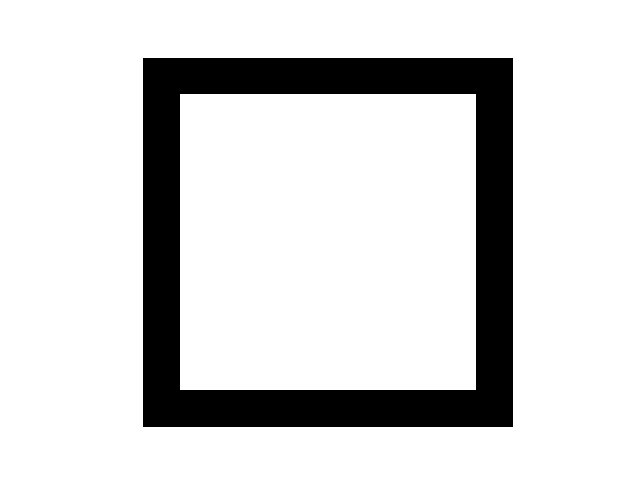

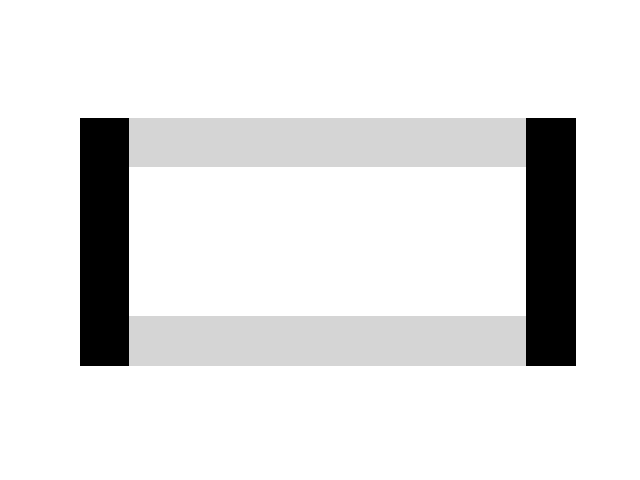

In [12]:
# Definir los datos de entrada y el kernel
# input_data = tf.random.normal([1, 6, 6, 1])  # Batch de 1 imagen de 10x10 píxeles en escala de grises
input_data = np.zeros([1, 10, 10, 1])  # Batch de 1 imagen de 10x10 píxeles en escala de grises
input_data[0, 1:-1, 1:-1, 0] = np.ones([8, 8])  # Batch de 1 imagen de 10x10 píxeles en escala de grises
# kernel_data = tf.random.normal([2, 1, 1, 1])   # Kernel de 6x1
kernel_data = np.ones([6, 1, 1, 1])   # Kernel de 6x1 con puros 1s

# Aplicar convolución 2D
conv_result = tf.nn.conv2d(input_data, kernel_data, strides=[1, 1, 1, 1], padding='VALID')

# Imprimir la forma del resultado
print("Forma del resultado de la convolución:", conv_result.shape)

input_data = np.reshape(input_data, (input_data.shape[1], input_data.shape[2]))
conv_result = np.reshape(conv_result, (conv_result.shape[1], conv_result.shape[2]))
kernel_data = np.reshape(kernel_data, (kernel_data.shape[0]))


print(input_data)
print()
print(conv_result)
print()

print(kernel_data)

fc.imgshow_matplotlib("", input_data)
fc.imgshow_matplotlib("", conv_result)

# la convolucion par se centra en filter_size -1 // 2 (el pixel del centro es el primero del centro)

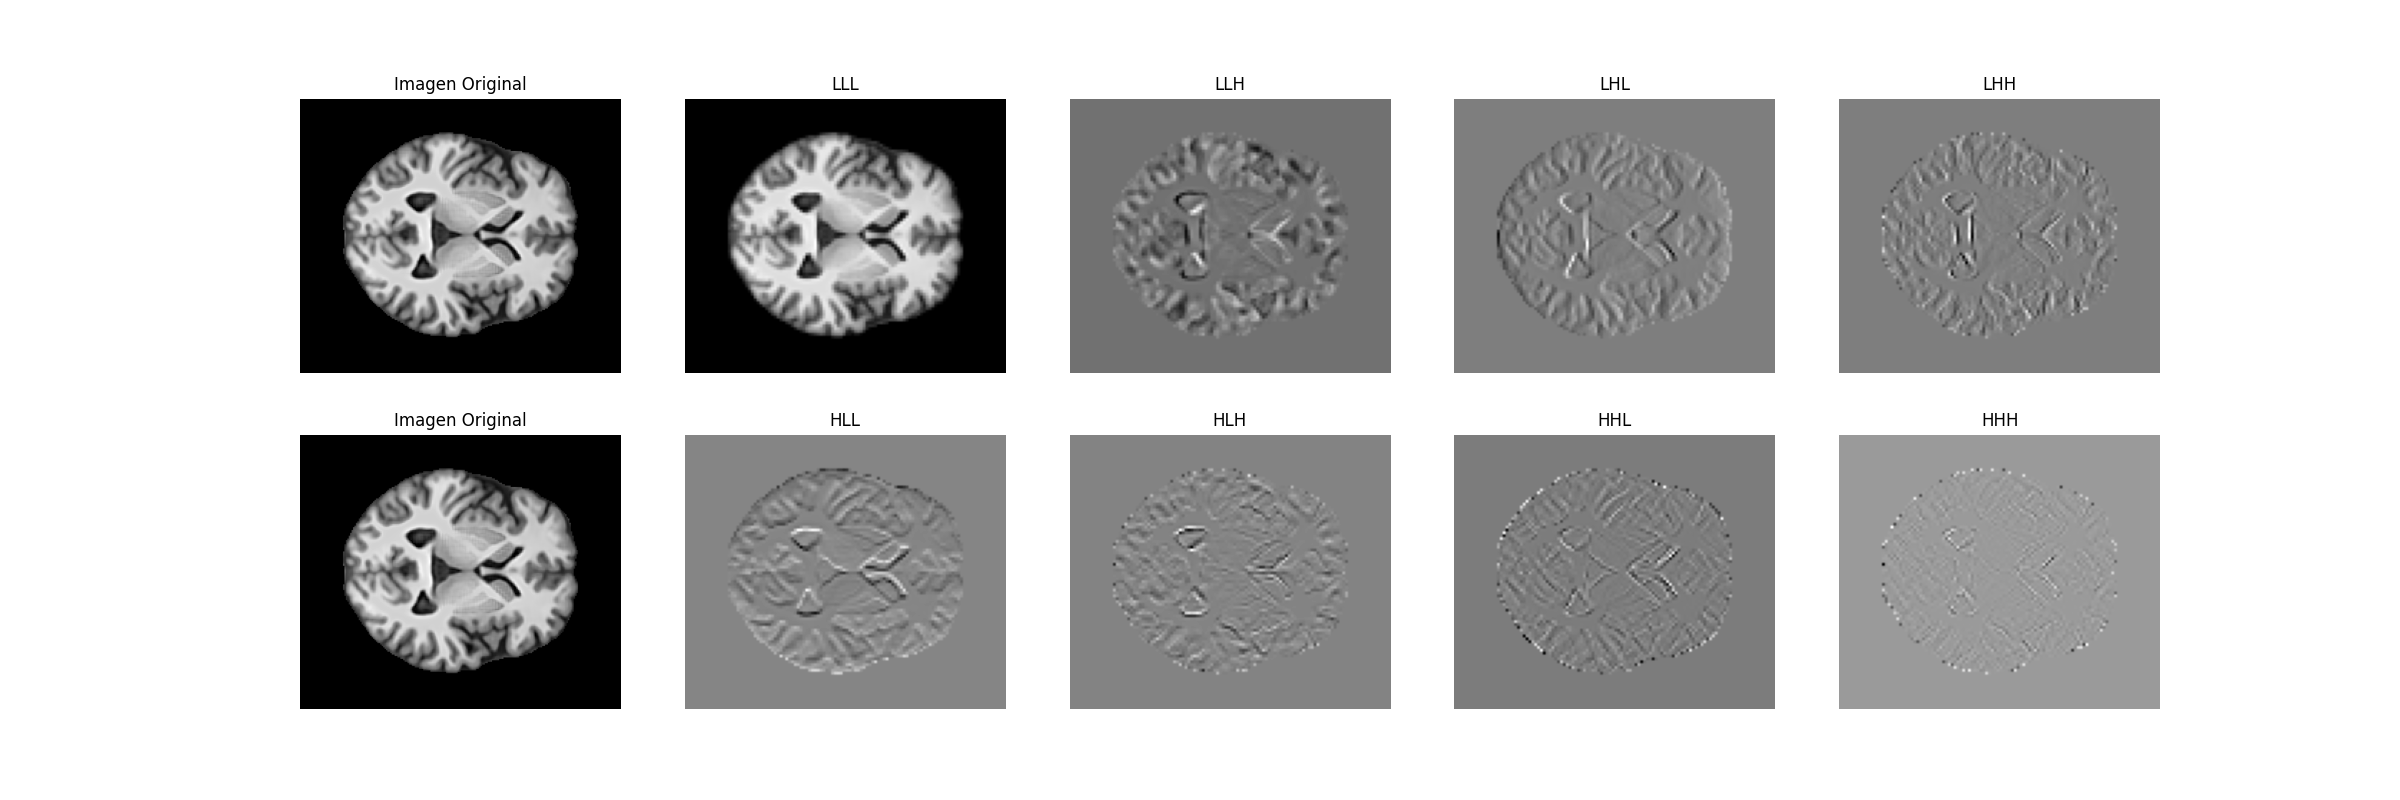

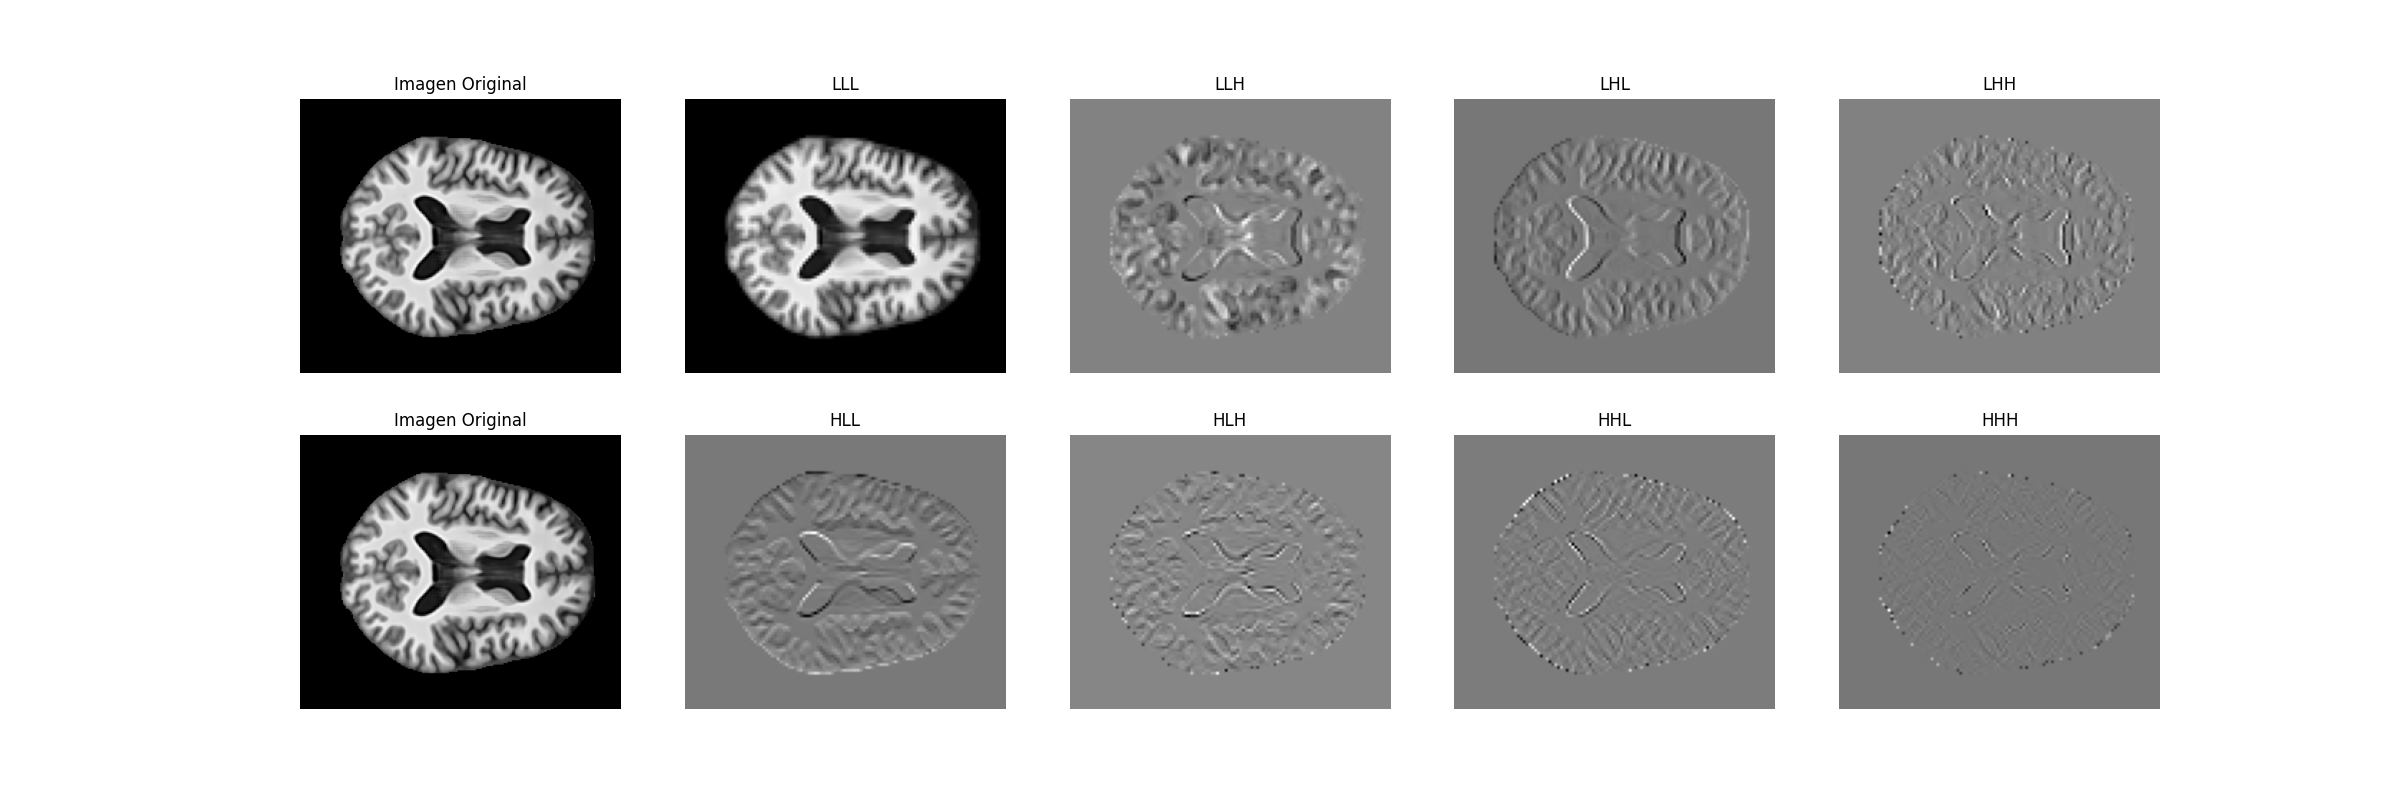

In [13]:
batch3D = np.concatenate([image3D, image3D2], axis=0)
# print(batch3D.shape)
res = wavelet_filter_3D_tensor(batch3D, "haar")
lll1, llh1, lhl1, lhh1, hll1, hlh1, hhl1, hhh1 = res[0,...,0], res[0,...,1], res[0,...,2], res[0,...,3], res[0,...,4], res[0,...,5], res[0,...,6], res[0,...,7]
lll2, llh2, lhl2, lhh2, hll2, hlh2, hhl2, hhh2 = res[1,...,0], res[1,...,1], res[1,...,2], res[1,...,3], res[1,...,4], res[1,...,5], res[1,...,6], res[1,...,7]

visualize_wevelet_filters_result3D(batch3D[0,...,0], lll1, llh1, lhl1, lhh1, hll1, hlh1, hhl1, hhh1, layer=50)
visualize_wevelet_filters_result3D(batch3D[1,...,0], lll2, llh2, lhl2, lhh2, hll2, hlh2, hhl2, hhh2, layer=50)


0.068995446


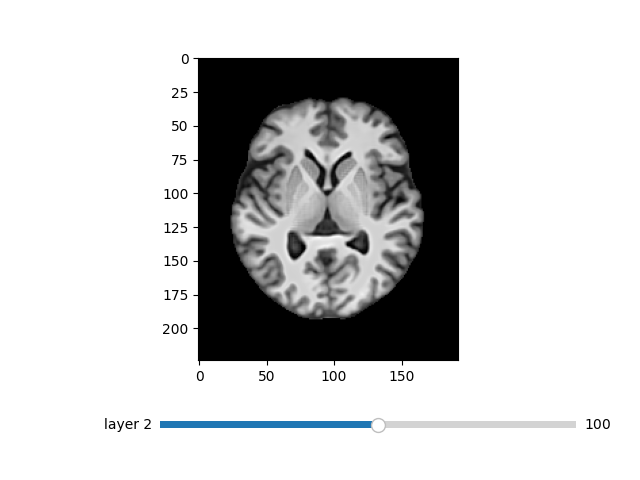

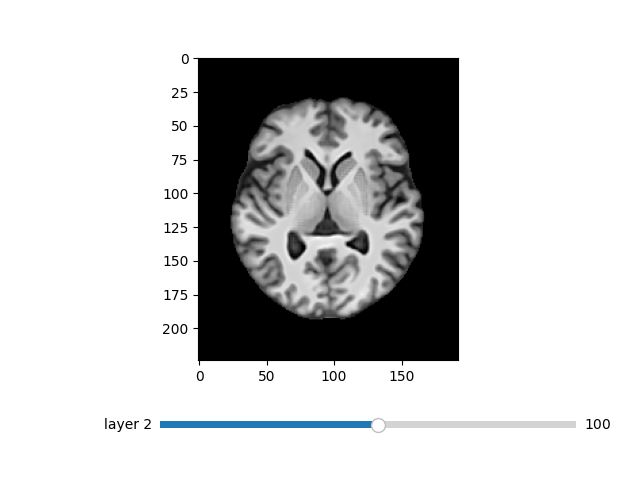

In [14]:
# res = wavelet_filter_3D_tensor(image3D, "haar")
# rec = inverse_wavelet_filter_3D(res, "haar")

dwtn_res = pywt.dwtn(image3D[0,...,0], 'haar')
img_rec = pywt.idwtn(dwtn_res, "haar", mode='symmetric', axes=None)

print(np.sum(np.abs(image3D[0,...,0] - img_rec)))


%matplotlib widget

fc.imgshow_3D("", image3D[0,...,0])
fc.imgshow_3D("", img_rec)

In [15]:
# print(image3D.shape)
dwtn_res = pywt.dwtn(image3D[0,...,0], 'bior1.3')
lll_dwtn, llh_dwtn, lhl_dwtn, lhh_dwtn, hll_dwtn, hlh_dwtn, hhl_dwtn, hhh_dwtn = dwtn_res["aaa"], dwtn_res["aad"], dwtn_res["ada"], dwtn_res["add"], dwtn_res["daa"], dwtn_res["dad"], dwtn_res["dda"], dwtn_res["ddd"]
lll, llh, lhl, lhh, hll, hlh, hhl, hhh = wavelet_filter_3D(image3D, "bior1.3")


# visualize_wevelet_filters_result3D(image3D[0,...,0], lll_dwtn, llh_dwtn, lhl_dwtn, lhh_dwtn, hll_dwtn, hlh_dwtn, hhl_dwtn, hhh_dwtn, layer=50)
# visualize_wevelet_filters_result3D(image3D[0,...,0], lll, llh, lhl, lhh, hll, hlh, hhl, hhh, layer=50)


# %matplotlib widget

# print(lll.shape)
# fc.imgshow_3D("llh_dwtn", llh_dwtn, current_plane=50)
# fc.imgshow_3D("lhh", hll, current_plane=50)
print(image3D.shape)
print(llh.shape)
print(llh_dwtn.shape)
# print(np.sum(np.abs(llh - llh_dwtn)))


(1, 192, 224, 192, 1)
(96, 112, 96)
(98, 114, 98)
